# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [1]:
%pip install pandas matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================


In [3]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("enterprise_database.db")

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print(tables)

    name
0  users


In [4]:
df_users = pd.read_sql_query("SELECT * FROM users LIMIT 5;", conn)

print(df_users)

   user_id          name     status           updated_at
0  U-00000  User_U-00000    Pending  2023-01-01 10:00:00
1  U-00000  User_U-00000     Active  2023-01-19 14:00:00
2  U-00000  User_U-00000  Suspended  2023-02-28 09:00:00
3  U-00001  User_U-00001    Pending  2023-01-01 10:00:00
4  U-00001  User_U-00001     Active  2023-01-28 14:00:00


In [5]:
query = """
WITH latest_users AS (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
)

SELECT
    user_id,
    name,
    status,
    updated_at
FROM latest_users
WHERE rn = 1
AND status = 'Active'
"""

df_active_users = pd.read_sql_query(query, conn)

print(df_active_users.head(10))

   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00
5  U-00008  User_U-00008  Active  2023-01-27 14:00:00
6  U-00011  User_U-00011  Active  2023-01-27 14:00:00
7  U-00015  User_U-00015  Active  2023-01-02 14:00:00
8  U-00017  User_U-00017  Active  2023-01-16 14:00:00
9  U-00019  User_U-00019  Active  2023-01-22 14:00:00


In [6]:
print("Total Active Customers:", len(df_active_users))

print("Unique Customers:", df_active_users["user_id"].nunique())

print("Duplicate Customers:", df_active_users["user_id"].duplicated().sum())

print("Statuses:")
print(df_active_users["status"].value_counts())

Total Active Customers: 14183
Unique Customers: 14183
Duplicate Customers: 0
Statuses:
status
Active    14183
Name: count, dtype: int64


In [7]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.

 

In [8]:
with open("server_logs.txt", "r", encoding="utf-8") as f:
    for _ in range(10):
        print(f.readline().rstrip())

Raw_Server_Log
"[2023-03-15 00:00:00] INFO: Transaction processed. payload={""u"":""U-19484"", ""item_code"":""PRD-874"", ""eur_val"":3404.44}"
"[2023-09-09 00:00:00] ERROR: Transaction processed. payload={""u"":""U-21438"", ""item_code"":""PRD-793"", ""failed_val"":41.24}"
"[2023-05-09 00:00:00] INFO: Transaction processed. payload={""u"":""U-18932"", ""item_code"":""PRD-905"", ""eur_val"":3406.21}"
"[2023-10-21 00:00:00] INFO: Transaction processed. payload={""u"":""U-15882"", ""item_code"":""PRD-284"", ""eur_val"":164.08}"
"[2023-01-10 00:00:00] INFO: Transaction processed. payload={""u"":""U-22781"", ""item_code"":""PRD-665"", ""eur_val"":26.8}"
"[2023-05-23 00:00:00] INFO: Transaction processed. payload={""u"":""U-13348"", ""item_code"":""PRD-589"", ""eur_val"":4964.77}"
"[2023-10-20 00:00:00] INFO: Transaction processed. payload={""u"":""U-22062"", ""item_code"":""PRD-363"", ""eur_val"":48.63}"
"[2023-12-02 00:00:00] INFO: Transaction processed. payload={""u"":""U-22146"", ""item

In [9]:
# Load server logs into a DataFrame
df_logs = pd.read_csv("server_logs.txt")

# Check total log records
print("Total Log Records:", len(df_logs))

# Remove ERROR records
df_logs = df_logs[~df_logs["Raw_Server_Log"].str.contains("ERROR", na=False)]

# Check remaining records
print("Records After Removing Errors:", len(df_logs))

Total Log Records: 100000
Records After Removing Errors: 94902


In [10]:
# Extract required information using Regex
extracted_data = df_logs["Raw_Server_Log"].str.extract(
    r'\[(.*?)\].*?"u":"(.*?)".*?"item_code":"(.*?)".*?"eur_val":([\d.]+)'
)

# Rename columns
extracted_data.columns = ["Date", "User ID", "Product ID", "Euro Value"]

# Convert Euro Value into numeric format
extracted_data["Euro Value"] = pd.to_numeric(extracted_data["Euro Value"])

# Display first 5 records
print(extracted_data.head())

                  Date  User ID Product ID  Euro Value
0  2023-03-15 00:00:00  U-19484    PRD-874     3404.44
2  2023-05-09 00:00:00  U-18932    PRD-905     3406.21
3  2023-10-21 00:00:00  U-15882    PRD-284      164.08
4  2023-01-10 00:00:00  U-22781    PRD-665       26.80
5  2023-05-23 00:00:00  U-13348    PRD-589     4964.77


In [11]:
# Validate extracted data
print("Total Extracted Records:", len(extracted_data))

print("\nMissing Values:")
print(extracted_data.isnull().sum())

print("\nData Types:")
print(extracted_data.dtypes)

Total Extracted Records: 94902

Missing Values:
Date          0
User ID       0
Product ID    0
Euro Value    0
dtype: int64

Data Types:
Date              str
User ID           str
Product ID        str
Euro Value    float64
dtype: object


In [12]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.


In [13]:
df_rates = pd.read_csv("daily_exchange_rates.csv")

print(df_rates.head(10))
print(df_rates.info())
print(df_rates.isnull().sum())

         Date  EUR_to_USD
0  2023-01-01    1.124836
1  2023-01-02    1.093087
2  2023-01-03    1.132384
3  2023-01-04    1.176151
4  2023-01-05    1.088292
5  2023-01-06         NaN
6  2023-01-07         NaN
7  2023-01-08    1.138372
8  2023-01-09    1.076526
9  2023-01-10    1.127128
<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        365 non-null    str    
 1   EUR_to_USD  261 non-null    float64
dtypes: float64(1), str(1)
memory usage: 5.8 KB
None
Date            0
EUR_to_USD    104
dtype: int64


In [14]:
# Fill missing exchange rates using forward fill
df_rates["EUR_to_USD"] = df_rates["EUR_to_USD"].ffill()

# Check missing values again
print(df_rates.isnull().sum())

# Display first 10 records
print(df_rates.head(10))

Date          0
EUR_to_USD    0
dtype: int64
         Date  EUR_to_USD
0  2023-01-01    1.124836
1  2023-01-02    1.093087
2  2023-01-03    1.132384
3  2023-01-04    1.176151
4  2023-01-05    1.088292
5  2023-01-06    1.088292
6  2023-01-07    1.088292
7  2023-01-08    1.138372
8  2023-01-09    1.076526
9  2023-01-10    1.127128


In [15]:
# Convert Date columns into datetime format
extracted_data["Date"] = pd.to_datetime(extracted_data["Date"]).dt.date
df_rates["Date"] = pd.to_datetime(df_rates["Date"]).dt.date

# Check data types
print(extracted_data["Date"].dtype)
print(df_rates["Date"].dtype)

object
object


In [16]:
# Merge extracted transactions with exchange rates
df_merged = pd.merge(
    extracted_data,
    df_rates,
    on="Date",
    how="left"
)

# Check merged data
print(df_merged.head())

# Check total records and missing exchange rates
print("Total Records:", len(df_merged))
print("Missing Exchange Rates:", df_merged["EUR_to_USD"].isnull().sum())

         Date  User ID Product ID  Euro Value  EUR_to_USD
0  2023-03-15  U-19484    PRD-874     3404.44    1.178232
1  2023-05-09  U-18932    PRD-905     3406.21    1.104983
2  2023-10-21  U-15882    PRD-284      164.08    1.075350
3  2023-01-10  U-22781    PRD-665       26.80    1.127128
4  2023-05-23  U-13348    PRD-589     4964.77    1.019626
Total Records: 94902
Missing Exchange Rates: 0


In [17]:
# Merge transactions with active customers
df_merged_users = pd.merge(
    df_merged,
    df_active_users,
    left_on="User ID",
    right_on="user_id",
    how="inner"
)

# Check merged data
print(df_merged_users.head())

print("\nTotal Records:", len(df_merged_users))
print("Unique Customers:", df_merged_users["User ID"].nunique())

         Date  User ID Product ID  Euro Value  EUR_to_USD  user_id  \
0  2023-03-15  U-19484    PRD-874     3404.44    1.178232  U-19484   
1  2023-10-21  U-15882    PRD-284      164.08    1.075350  U-15882   
2  2023-01-10  U-22781    PRD-665       26.80    1.127128  U-22781   
3  2023-10-20  U-22062    PRD-363       48.63    1.075350  U-22062   
4  2023-12-02  U-22146    PRD-223      960.60    1.066142  U-22146   

           name  status           updated_at  
0  User_U-19484  Active  2023-01-11 14:00:00  
1  User_U-15882  Active  2023-01-16 14:00:00  
2  User_U-22781  Active  2023-01-07 14:00:00  
3  User_U-22062  Active  2023-01-05 14:00:00  
4  User_U-22146  Active  2023-01-18 14:00:00  

Total Records: 53899
Unique Customers: 13888


In [18]:
# Create final DataFrame
df_final = df_merged_users.copy()

# Calculate revenue in USD
df_final["USD_Revenue"] = (
    df_final["Euro Value"] * df_final["EUR_to_USD"]
)

# Display final data
print(df_final.head())

# Check total records and missing values
print("\nTotal Records:", len(df_final))
print("\nMissing Values:")
print(df_final.isnull().sum())

         Date  User ID Product ID  Euro Value  EUR_to_USD  user_id  \
0  2023-03-15  U-19484    PRD-874     3404.44    1.178232  U-19484   
1  2023-10-21  U-15882    PRD-284      164.08    1.075350  U-15882   
2  2023-01-10  U-22781    PRD-665       26.80    1.127128  U-22781   
3  2023-10-20  U-22062    PRD-363       48.63    1.075350  U-22062   
4  2023-12-02  U-22146    PRD-223      960.60    1.066142  U-22146   

           name  status           updated_at  USD_Revenue  
0  User_U-19484  Active  2023-01-11 14:00:00  4011.220772  
1  User_U-15882  Active  2023-01-16 14:00:00   176.443420  
2  User_U-22781  Active  2023-01-07 14:00:00    30.207030  
3  User_U-22062  Active  2023-01-05 14:00:00    52.294268  
4  User_U-22146  Active  2023-01-18 14:00:00  1024.135923  

Total Records: 53899

Missing Values:
Date           0
User ID        0
Product ID     0
Euro Value     0
EUR_to_USD     0
user_id        0
name           0
status         0
updated_at     0
USD_Revenue    0
dtype: int

In [19]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.



In [20]:
# Convert Date column into datetime format
df_final["Date"] = pd.to_datetime(df_final["Date"])

# Group revenue by month
monthly_revenue = df_final.groupby(
    df_final["Date"].dt.to_period("M")
)["USD_Revenue"].sum().reset_index()

# Display monthly revenue
print(monthly_revenue)

       Date   USD_Revenue
0   2023-01  1.284176e+07
1   2023-02  1.143613e+07
2   2023-03  1.234893e+07
3   2023-04  1.201538e+07
4   2023-05  1.233364e+07
5   2023-06  1.208436e+07
6   2023-07  1.244416e+07
7   2023-08  1.281273e+07
8   2023-09  1.222895e+07
9   2023-10  1.250133e+07
10  2023-11  1.258822e+07
11  2023-12  1.263902e+07


In [21]:
# Calculate total spending by each customer
top_customers = df_final.groupby(
    "User ID"
)["USD_Revenue"].sum().reset_index()

# Sort customers by revenue (highest first)
top_customers = top_customers.sort_values(
    by="USD_Revenue",
    ascending=False
)

# Select Top 5 customers
top_5_customers = top_customers.head(5)

# Display Top 5 customers
print(top_5_customers)

       User ID   USD_Revenue
3613   U-06582  40050.988262
12937  U-23313  39555.806629
2078   U-03805  39529.945085
11066  U-20018  38649.965242
3553   U-06489  38629.142146


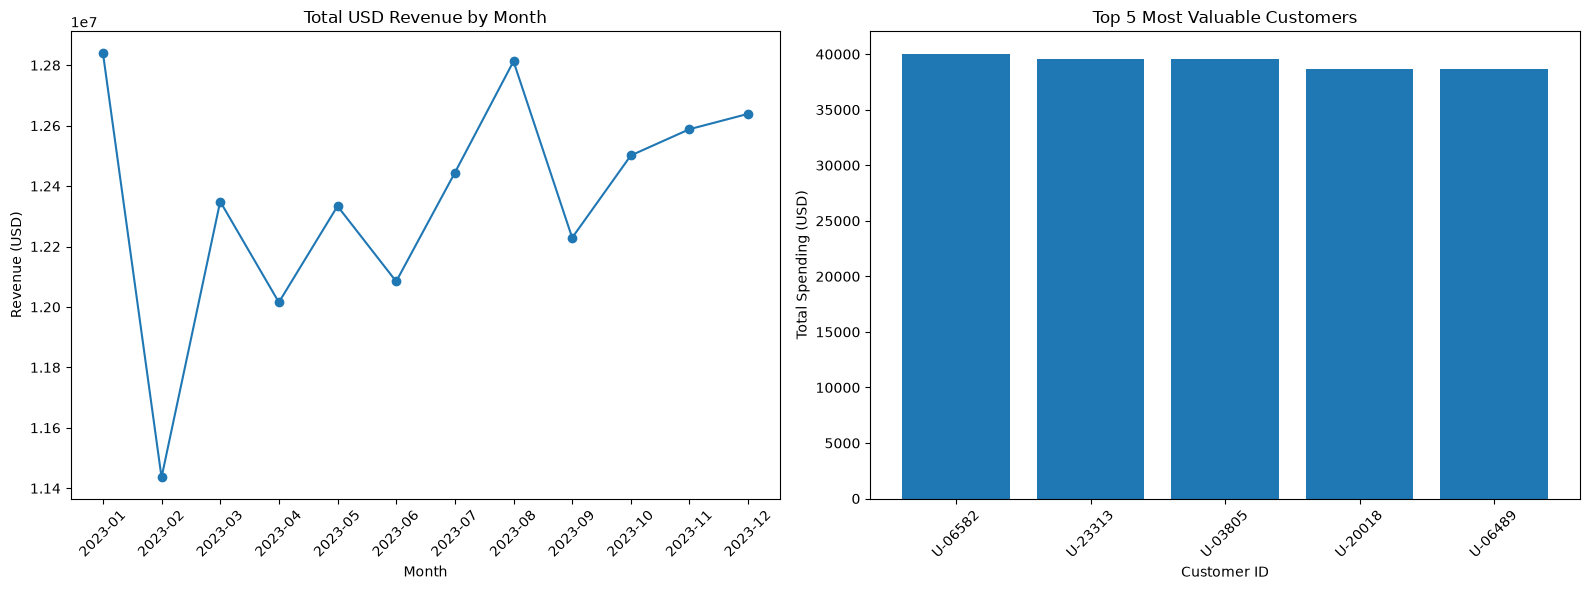

In [22]:
import matplotlib.pyplot as plt

# Create two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Monthly Revenue
axes[0].plot(
    monthly_revenue["Date"].astype(str),
    monthly_revenue["USD_Revenue"],
    marker="o"
)

axes[0].set_title("Total USD Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (USD)")
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Top 5 Customers
axes[1].bar(
    top_5_customers["User ID"],
    top_5_customers["USD_Revenue"]
)

axes[1].set_title("Top 5 Most Valuable Customers")
axes[1].set_xlabel("Customer ID")
axes[1].set_ylabel("Total Spending (USD)")
axes[1].tick_params(axis="x", rotation=45)

# Adjust layout and display charts
plt.tight_layout()
plt.show()

In [23]:
# Final project validation

print("Total Transactions:", len(df_final))

print("Unique Customers:", df_final["User ID"].nunique())

print("Missing Values:")
print(df_final.isnull().sum())

print("\nCustomer Status:")
print(df_final["status"].value_counts())

print("\nTotal USD Revenue:")
print(round(df_final["USD_Revenue"].sum(), 2))

Total Transactions: 53899
Unique Customers: 13888
Missing Values:
Date           0
User ID        0
Product ID     0
Euro Value     0
EUR_to_USD     0
user_id        0
name           0
status         0
updated_at     0
USD_Revenue    0
dtype: int64

Customer Status:
status
Active    53899
Name: count, dtype: int64

Total USD Revenue:
148274622.91


In [24]:
print("----- LOG EXTRACTION -----")
print("Valid log rows:", len(df_logs))
print("Extracted rows:", len(extracted_data))
print("Rows with missing extracted data:",
      extracted_data.isnull().any(axis=1).sum())

print("\n----- EXCHANGE RATES -----")
print("Rate rows:", len(df_rates))
print("Missing rates:", df_rates["EUR_to_USD"].isnull().sum())
print("Duplicate dates:", df_rates["Date"].duplicated().sum())
print("Rate date range:", df_rates["Date"].min(), "to", df_rates["Date"].max())

print("\n----- MERGING -----")
print("After exchange rate merge:", len(df_merged))
print("Transactions without exchange rate:",
      df_merged["EUR_to_USD"].isnull().sum())
print("After active customer merge:", len(df_merged_users))
print("Final transactions:", len(df_final))

----- LOG EXTRACTION -----
Valid log rows: 94902
Extracted rows: 94902
Rows with missing extracted data: 0

----- EXCHANGE RATES -----
Rate rows: 365
Missing rates: 0
Duplicate dates: 0
Rate date range: 2023-01-01 to 2023-12-31

----- MERGING -----
After exchange rate merge: 94902
Transactions without exchange rate: 0
After active customer merge: 53899
Final transactions: 53899


In [25]:
df_rates_original = pd.read_csv("daily_exchange_rates.csv")

print("Original Missing Rates:",
      df_rates_original["EUR_to_USD"].isnull().sum())

print("Missing Rates After Forward Fill:",
      df_rates["EUR_to_USD"].isnull().sum())

Original Missing Rates: 104
Missing Rates After Forward Fill: 0


# PROJECT CONCLUSION

## Key Findings

- Successfully extracted 94,902 valid transactions from server logs.
- Removed 5,098 ERROR records.
- Filled missing exchange rates using Forward Fill.
- Integrated transaction data with exchange rates and active customers.
- Calculated total revenue in USD.
- Identified the Top 5 Most Valuable Customers.
- Created a monthly revenue trend and Top 5 Customers dashboard.

## Final Results

- Total Transactions: 53,899
- Unique Active Customers: 13,888
- Missing Values: 0
- Total USD Revenue: $148,274,622.91

## Conclusion

The project successfully reconciles transaction data, customer records, and exchange rates to analyze genuine revenue from active customers.
